#REGRESSION ANALYSIS FOR HAPPINESS INDEX 2018-2019 DATASET

##Referensi
####Dataset by Sougata Pramanick(2022)
####https://www.kaggle.com/datasets/sougatapramanick/happiness-index-2018-2019

###Import Dataset

In [15]:
import pandas as pd

data ="/content/2018.csv"
df = pd.read_csv(data)
df.head(10)

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.632,1.305,1.592,0.874,0.681,0.202,0.393
1,2,Norway,7.594,1.456,1.582,0.861,0.686,0.286,0.340
2,3,Denmark,7.555,1.351,1.590,0.868,0.683,0.284,0.408
3,4,Iceland,7.495,1.343,1.644,0.914,0.677,0.353,0.138
4,5,Switzerland,7.487,1.420,1.549,0.927,0.660,0.256,0.357
5,6,Netherlands,7.441,1.361,1.488,0.878,0.638,0.333,0.295
6,7,Canada,7.328,1.330,1.532,0.896,0.653,0.321,0.291
7,8,New Zealand,7.324,1.268,1.601,0.876,0.669,0.365,0.389
8,9,Sweden,7.314,1.355,1.501,0.913,0.659,0.285,0.383
9,10,Australia,7.272,1.340,1.573,0.910,0.647,0.361,0.302


###Statistika Deskriptif

In [16]:
df_reg = df[["Score","GDP per capita","Healthy life expectancy","Social support","Perceptions of corruption"]]
df_reg.describe()

,Score,GDP per capita,Healthy life expectancy,Social support,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000
mean,5.375917,0.891449,0.597346,1.213237,0.112449
std,1.119506,0.391921,0.247579,0.302372,0.096343
min,2.905000,0.000000,0.000000,0.000000,0.000000
25%,4.453750,0.616250,0.422250,1.066750,0.051000
50%,5.378000,0.949500,0.644000,1.255000,0.082000
75%,6.168500,1.197750,0.777250,1.463000,0.139000
max,7.632000,2.096000,1.030000,1.644000,0.457000


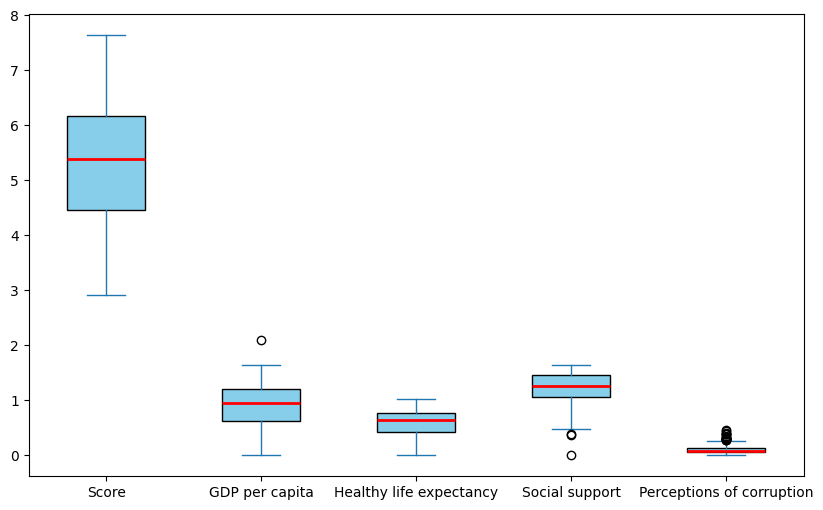

In [17]:
import matplotlib.pyplot as plt

# Memilih beberapa variabel numerik
variabel = ['Score', 'GDP per capita', 'Healthy life expectancy', 'Social support', 'Perceptions of corruption']

# Membuat boxplot
df[variabel].plot.box(
    patch_artist=True,
    figsize=(10, 6),
    boxprops=dict(facecolor='skyblue'),
    medianprops=dict(color='red', linewidth=2)
)

plt.show()


##Visualisasi dan Analisis Korelasi Sederhana

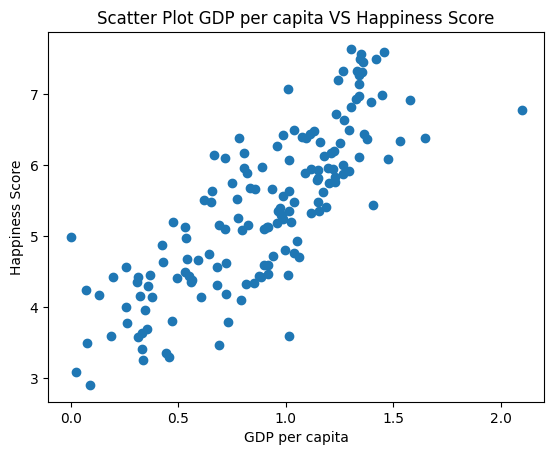

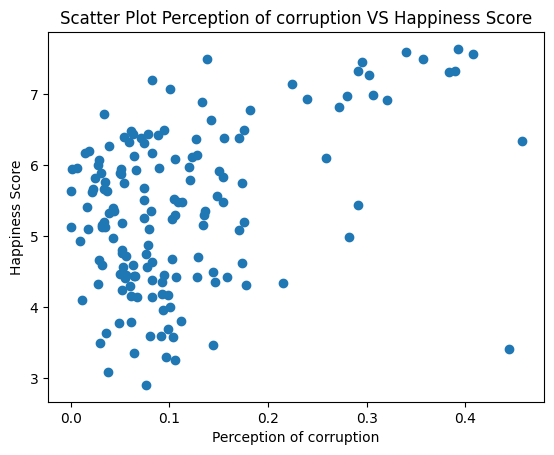

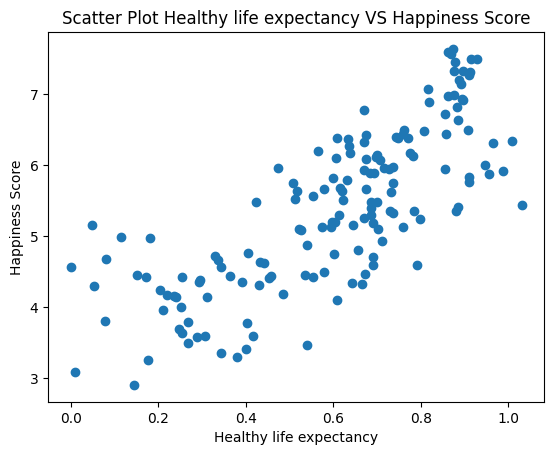

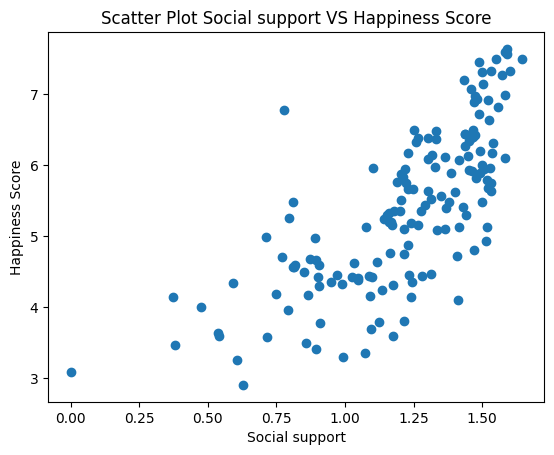

In [ ]:
#Visualisasi Scatter Plot CGPA dengan Study Hours dan CGPA dengan Sleep Duration

plt.scatter(df["GDP per capita"], df["Score"])
plt.xlabel("GDP per capita")
plt.ylabel("Happiness Score")
plt.title("Scatter Plot GDP per capita VS Happiness Score")
plt.show()

plt.scatter(df["Perceptions of corruption"], df["Score"])
plt.xlabel("Perception of corruption")
plt.ylabel("Happiness Score")
plt.title("Scatter Plot Perception of corruption VS Happiness Score")
plt.show()

plt.scatter(df["Healthy life expectancy"], df["Score"])
plt.xlabel("Healthy life expectancy")
plt.ylabel("Happiness Score")
plt.title("Scatter Plot Healthy life expectancy VS Happiness Score")
plt.show()

plt.scatter(df["Social support"], df["Score"])
plt.xlabel("Social support")
plt.ylabel("Happiness Score")
plt.title("Scatter Plot Social support VS Happiness Score")
plt.show()





#####Keempat grafik menunjukkan pola data yang serupa yaitu naik. Distribusi data untuk happiness score dengan GDP per capita menunjukkan pola yang paling rapat dibanding variabel lainnya dapat diasumsikan variabel tersebut memiliki hubungan asosiatif yang kuat dengan variabel target (happiness score)

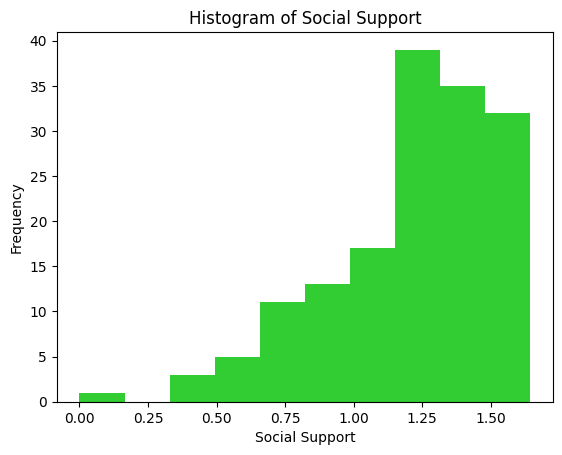

In [ ]:
#Visualisasi Bar Chart Variabel Depression
df["Social support"].hist(
    bins=10,
    color='limegreen',
    grid = False
)

plt.title(f'Histogram of Social Support')
plt.xlabel("Social Support")
plt.ylabel('Frequency')
plt.show()

#####Distribusi histogram di atas menunjukkan bentuk yang menceng ke kiri sedangkan sebagian besar data terdistribusi di bagian kanan. Hal ini dikarenakan adanya outlier di bawah data

In [ ]:
# Nilai Korelasi Happiness Score dengan Variabel-Variabel Prediktor
corr_1 = df["GDP per capita"].corr(df["Score"])
print("GDP per capita :", corr_1)

corr_2 = df["Healthy life expectancy"].corr(df["Score"])
print("Healthy life expectancy :", corr_2)

corr_3 = df["Social support"].corr(df["Score"])
print("Social support :", corr_3)

corr_4 = df["Perceptions of corruption"].corr(df["Score"])
print("Perceptions of corruption :", corr_4)


GDP per capita : 0.8021239467301907
Healthy life expectancy : 0.7758136033302464
Social support : 0.7457601649725755
Perceptions of corruption : 0.40840527966777723


######Variabel GDP per capita, healthy life expectancy, dan social support menunjukkan hubungan korelasi positif yang kuat sedangkan untuk variabel Perceptions of corruption positif yang cenderung ,lebih lemah.


#Simple Linear Regression

###Fitting Model


In [23]:
from sklearn.model_selection import train_test_split

X = df_reg[['GDP per capita']]
y = df_reg['Score']
X_train, X_test,y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [24]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [25]:
b0 = float(model.intercept_)
b1 = float(model.coef_[0])
print(f"Model colab : Happiness_Score_Prediction = "
f"{b0:.3f} + ({b1:.3f}) x GDP per capita")

Model colab : Happiness_Score_Prediction = 3.211 + (2.441) x GDP per capita


####Nilai koefisien menunjukkan angka yang positif, ini artinya variabel GDP per capita memiliki hubungan yang positif atau searah dengan skor kebahagiaan. Semakin tinggi GDP per capita, maka semakin tinggi skor kebahagiaan penduduk.

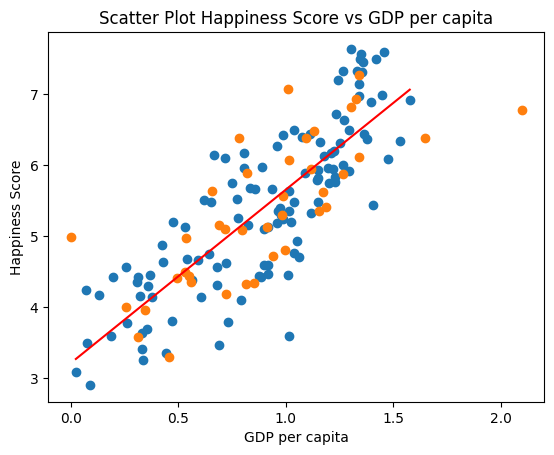

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x_grid = pd.DataFrame(
    {"GDP per capita" : np.linspace(X_train["GDP per capita"].min(),
        X_train["GDP per capita"].max(),300)})
y_grid = model.predict(x_grid)

plt.scatter(X_train['GDP per capita'], y_train, label='Train Data')
plt.scatter(X_test["GDP per capita"], y_test, label='Test Data')
plt.xlabel("GDP per capita")
plt.ylabel("Happiness Score")
plt.title("Scatter Plot Happiness Score vs GDP per capita")
plt.plot(x_grid["GDP per capita"], y_grid, color='red', label='Regression Line')

#####Sebaran plot untuk nilai aktual X membentuk pola naik yang lumayan rapat dan mengikuti garis lurus prediksi. Akan tetapi ada beberapa nilai observasi yang menyimpang jauh dari nilai prediksi dibuktikan dengan letak titiknya yang jauh dari garis prediksi.

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pred_test = model.predict(X_test)
mae_slr = mean_absolute_error(y_test,pred_test)
rmse_slr = np.sqrt(mean_squared_error(y_test,pred_test))
r2_slr = r2_score(y_test,pred_test)
print("mae :", mae_slr)
print("rmse :", rmse_slr)
print("r2 :", r2_slr)

mae : 0.5621155443388103
rmse : 0.7077425337159496
r2 : 0.5002148008935017


In [27]:
rata_rata = sum(df['Score'])/len(df['Score'])
print(round(mae_slr/rata_rata * 100,2),"%")

10.46 %


In [28]:
import numpy as np
from sklearn.metrics import mean_squared_error

nrmse_slr = (rmse_slr / y_test.mean()) * 100
print(f"NRMSE: {nrmse:.2f}%")

NRMSE: 13.23%


#####Persentase Nilai MAE pada model tersebut sebesar 10.46% dan RMSE sebesar 13.23% jika diukur dengan rata-rata variabel y nya, sehingga dapat dikatakan errornya relatif sedang. Sedangkan, nilai R square untuk model ini adalah 0,5 yang dimana angka ini berada di tengah-tengah. Ini menunjukkan bahwa model yang dibuat tidak baik dan juga tidak buruk.

---

# Multiple Linear Regression



---

Cell 1: Import Library

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Cell 2: Membaca Dataset

In [4]:
#Scanning
df = pd.read_csv("/content/2018.csv")

# Menampilkan 5 data teratas
print("--------------------------------------- 5 DATA TERATAS ---------------------------------------")
df.head()

--------------------------------------- 5 DATA TERATAS ---------------------------------------


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.632,1.305,1.592,0.874,0.681,0.202,0.393
1,2,Norway,7.594,1.456,1.582,0.861,0.686,0.286,0.340
2,3,Denmark,7.555,1.351,1.590,0.868,0.683,0.284,0.408
3,4,Iceland,7.495,1.343,1.644,0.914,0.677,0.353,0.138
4,5,Switzerland,7.487,1.420,1.549,0.927,0.660,0.256,0.357


Cell 3: Variabel X dan Y

In [32]:
#Menentukan Variabel X dan Y
kolom_x = ['GDP per capita','Social support',
           'Healthy life expectancy',
           'Perceptions of corruption',
]
X_MLR = df[kolom_x]
y_MLR = df['Score']

Cell 4: Model dan Prediksi

In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

#Membuat dan Melatih Model Regresi Linear Berganda
X_MLR_train, X_MLR_test, y_MLR_train, y_MLR_test = train_test_split(X_MLR, y_MLR, test_size=0.2, random_state=2026)
model = LinearRegression()
model.fit(X_MLR_train, y_MLR_train)

# Melakukan prediksi
y_MLR_pred = model.predict(X_MLR_test)

# Menampilkan Persamaan Model
print('\n--- PERSAMAAN MODEL ---')
print('Intercept (b0):', model.intercept_)
for nama_kolom, koef in zip(kolom_x, model.coef_):
  print(f'Koefisien {nama_kolom}: {koef}')


--- PERSAMAAN MODEL ---
Intercept (b0): 2.251280783209816
Koefisien GDP per capita: 1.0091135114563208
Koefisien Social support: 1.2992693597442981
Koefisien Healthy life expectancy: 0.8137035967741796
Koefisien Perceptions of corruption: 1.7526232168343665


Cell 5: Scatter Plot

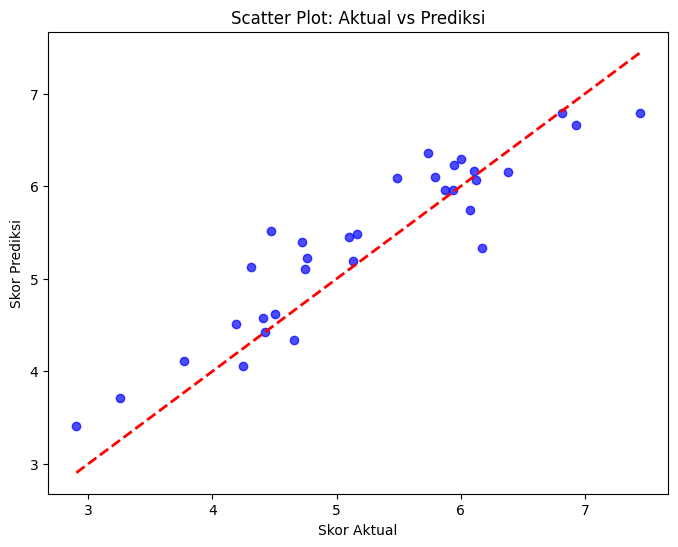

In [34]:
import matplotlib.pyplot as plt

#Scatter Plot: Actual vs Prediction
plt.figure(figsize=(8, 6))
plt.scatter(y_MLR_test, y_MLR_pred, color='blue', alpha=0.7)
plt.plot(
    [y_MLR_test.min(), y_MLR_test.max()], [y_MLR_test.min(), y_MLR_test.max()],
    color='red',
    linestyle='--',
    linewidth=2,
)
plt.xlabel('Skor Aktual')
plt.ylabel('Skor Prediksi')
plt.title('Scatter Plot: Aktual vs Prediksi')
plt.show()

Cell 6: Evaluasi Model Terhadap Error

In [36]:
#Menghitung Evaluasi Model (MAE, RMSE, R^2)
mae = mean_absolute_error(y_MLR_test, y_MLR_pred)
rmse = np.sqrt(mean_squared_error(y_MLR_test, y_MLR_pred))
r2 = r2_score(y_MLR_test, y_MLR_pred)

print('\n--- EVALUASI MODEL ---')
print(f'MAE  : {mae}')
print(f'RMSE : {rmse}')
print(f'R^2  : {r2}')


--- EVALUASI MODEL ---
MAE  : 0.34953349668452904
RMSE : 0.4345229155206138
R^2  : 0.8285505013668428


In [38]:
print(round(mae / (sum(df['Score'])/len(df['Score'])) * 100,2),"%")

6.5 %


In [39]:
print(round(rmse / (sum(df['Score'])/len(df['Score'])) * 100,2),"%")

8.08 %


#####Persentase Nilai MAE pada model tersebut sebesar 6.5% dan RMSE sebesar 8.08% jika diukur dengan rata-rata variabel y nya, sehingga dapat dikatakan errornya relatif kecil. Sedangkan, nilai R square untuk model ini adalah 0,82 yang artinya model prediksi di atas cukup layak digunakan

Cell 7: Perbandingan Residu dan Prediksi

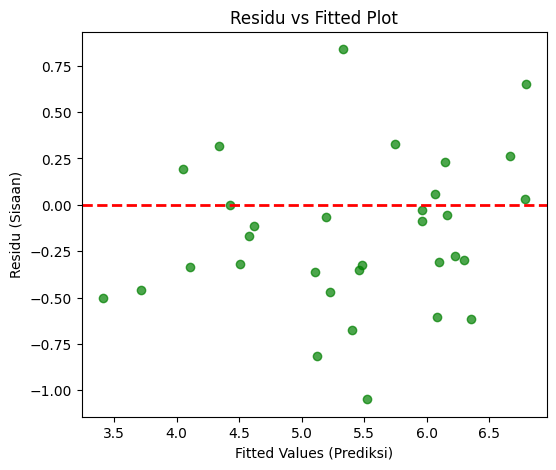

In [ ]:
#Residu vs Fitted Plot
residu = y_test - y_pred

plt.figure(figsize=(6, 5))
plt.scatter(y_pred, residu, color='green', alpha=0.7)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Fitted Values (Prediksi)')
plt.ylabel('Residu (Sisaan)')
plt.title('Residu vs Fitted Plot')
plt.show()

Cell 8: Show Q-Q Plot

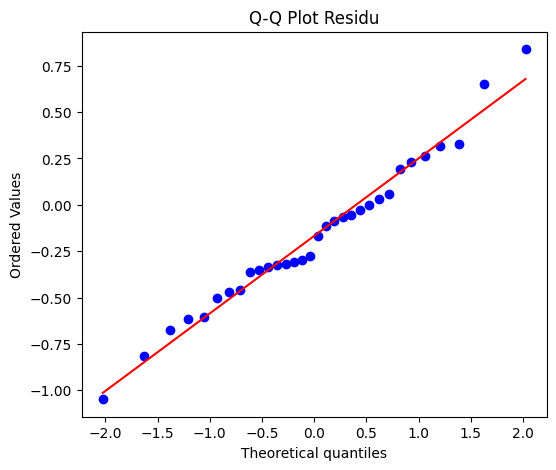

In [ ]:
#Q-Q Plot untuk Normalitas Residu
plt.figure(figsize=(6, 5))
stats.probplot(residu, dist='norm', plot=plt)
plt.title('Q-Q Plot Residu')
plt.show()

Cell 9: Multikolinearitas

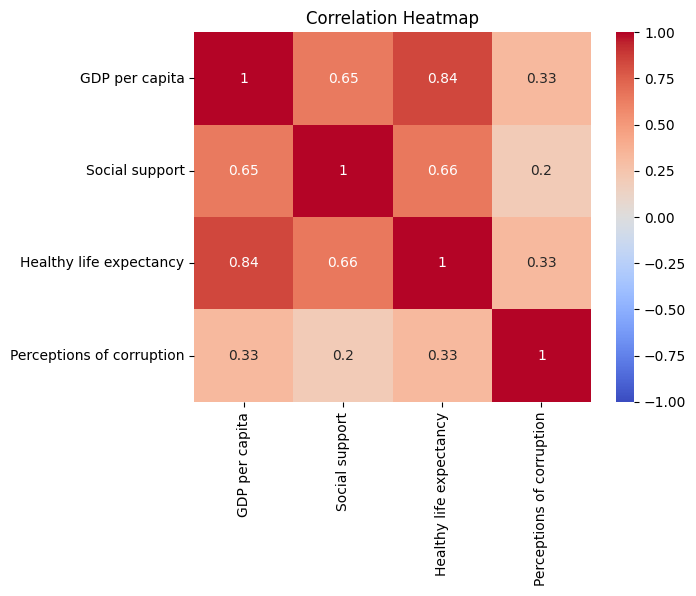

In [ ]:
#Melihat Adanya Multikolinearitas Menggunakan HeatMap
import seaborn as sns
import matplotlib.pyplot as plt

corr = X_train.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap')
plt.show()

####Jika dilihat dari Correlation HeatMap untuk masing-masing variabel prediktor, beberapa variabel memiliki nilai korelasi yang cukup tinggi, artinya kedua variabel prediktor tersebut memiliki hubungan tertentu dan perlu dicurigakan adanya multikolinearitas.

In [ ]:
#Multikolinearitas (VIF Sederhana)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

X_sm = sm.add_constant(X_train)
print('\n--- NILAI VIF (Multikolinearitas) ---')
for i in range(X_sm.shape[1]):
  vif = variance_inflation_factor(X_sm.values, i)
  print(f'{X_sm.columns[i]}: {vif}')


--- NILAI VIF (Multikolinearitas) ---
const: 1.0
GDP per capita: 3.6933277861313774
Social support: 1.859808649291448
Healthy life expectancy: 3.7535904604112065
Perceptions of corruption: 1.1326459492740495


####Karena nilai VIF nya cukup rendah untuk keseluruhan ( <5), maka variabel-variabel tersebut tidak terjadi multikolinearitas dan cukup aman digunakan sebagai prediktor model prediksi.

---

### **Kesimpulan Analisis Regresi Linear Berganda (MLR)**

1. **Performa & Kecocokan Model ($R^2$):**
* Berdasarkan hasil evaluasi model, diperoleh nilai Koefisien Determinasi ($R^2$) sebesar **0.8285 (82.85%)**.
* Model regresi linear berganda yang dibangun sudah sangat baik karena **82.85% variasi dari Skor Kebahagiaan (`Score`)** di berbagai negara dapat dijelaskan secara bersama-sama oleh keempat variabel prediktor ($X$) dalam model (yaitu *GDP per capita, Social support, Healthy life expectancy,* dan *Perceptions of corruption*). Sisa sekitar 21.05% dipengaruhi oleh faktor lain di luar model.


2. **Tingkat Akurasi (MAE & RMSE):**
* Nilai **MAE (0.349)** dan **RMSE (0.435)** yang relatif kecil menunjukkan bahwa rata-rata kesalahan prediksi dari model ini cukup rendah terhadap skor kebahagiaan aktual di dunia, sehingga model cukup akurat untuk melakukan estimasi.


3. **Pengaruh Variabel Prediktor:**
* Seluruh variabel independen menunjukkan koefisien regresi bernilai positif. Ini mengindikasikan bahwa peningkatan pada faktor ekonomi (*GDP*), dukungan sosial, kesehatan, maupun persepsi terhadap rendahnya korupsi secara konsisten sejalan dengan peningkatan skor kebahagiaan suatu negara.


4. **Uji Asumsi & Kelayakan Model:**
* **Multikolinearitas (VIF):** Semua variabel memiliki nilai VIF di bawah 10 (tertinggi sekitar 3.69 pada *GDP per capita*). Hal ini membuktikan bahwa **tidak ada masalah multikolinearitas yang serius**, sehingga masing-masing variabel prediktor memberikan informasi yang unik dan independen ke dalam model.
* **Diagnostik Residu (Plot Residu & Q-Q Plot):** Pola sebaran sisaan (*residuals*) relatif menyebar secara acak di sekitar garis nol dan mendekati garis normal pada *Q-Q plot*, menandakan asumsi dasar regresi linear terpenuhi dengan baik.



---

